In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import sys
sys.path.append('../')
from src.data.bag_generator import generate_hierarchical_bags

In [3]:
sampled_data = pd.read_parquet('../data/multi-class/amazon/train.parquet')
sampled_data.head()

,id,embeddings,label
0,0,"[0.0759083, 0.06751319, -0.012894456, 0.022475...",grocery_gourmet_food.meat_poultry.jerky
1,1,"[-0.051283453, 0.050382987, 0.00010905033, 0.0...",toys_games.games.unknown
2,2,"[-0.02359446, -0.012662321, -0.015545733, 0.04...",toys_games.games.unknown
3,3,"[-0.031092335, 0.025283827, -0.021664308, 0.01...",toys_games.games.unknown
4,4,"[-0.01096543, -0.056987703, 0.010365347, 0.032...",toys_games.puzzles.jigsaw_puzzles


In [4]:
bags_generated = generate_hierarchical_bags(
  sampled_data['embeddings'].values,
  sampled_data['label'].values
)

In [6]:
def visualizar_shifts_das_bags(bags):
  """
  Recebe a lista de bags geradas e plota a prevalência das classes folha
  para cada bag, separando visualmente os shifts uniformes dos extremos.
  """
  dados_plot = []
  
  # 1. Extrair as prevalências reais de cada bag
  for i, bag in enumerate(bags):
    y_bag = bag['y']
    total_amostras = len(y_bag)
    
    # Ignora bags vazias (caso extremo da falta de dados)
    if total_amostras == 0:
      continue
        
    contagem = Counter(y_bag)
    alpha = bag['alpha_shift']
    tipo_shift = "Uniforme (α=1.0)" if alpha == 1.0 else "Extremo (α=0.1)"
    
    # Nome único para a barra no eixo X
    nome_bag = f"Bag {i+1}\n{tipo_shift}\n(n={total_amostras})"
    
    for classe, qtd in contagem.items():
      prevalencia = qtd / total_amostras
      dados_plot.append({
        "Bag": nome_bag,
        "Tipo Shift": tipo_shift,
        "Classe": classe,
        "Prevalencia": prevalencia
      })
          
  # Converte para DataFrame do Pandas para facilitar o plot
  df = pd.DataFrame(dados_plot)
  
  # Organiza os dados no formato: Linhas=Bags, Colunas=Classes, Valores=Prevalências
  df_pivot = df.pivot(index="Bag", columns="Classe", values="Prevalencia").fillna(0)
  
  # Ordena o índice para que as bags Uniformes fiquem de um lado e as Extremas do outro
  df_pivot = df_pivot.sort_index(key=lambda x: x.str.contains("Extremo"))
  
  # 2. Configuração do Gráfico
  fig, ax = plt.subplots(figsize=(14, 7))
  
  # Cores categóricas do matplotlib (colormap 'tab10' ou 'Set2' são ótimos)
  df_pivot.plot(kind='bar', stacked=True, colormap='Set2', ax=ax, edgecolor='black', linewidth=0.5)
  
  # Estilização
  ax.set_title("Composição das Bags de Teste: Uniforme vs Extremo", fontsize=16, pad=20)
  ax.set_ylabel("Prevalência (Proporção)", fontsize=12)
  ax.set_xlabel("")
  ax.set_ylim(0, 1.0)
  
  # Linha horizontal em y=1.0 apenas para fechar a caixa do gráfico
  ax.axhline(1.0, color='black', linewidth=1)
  
  # Move a legenda para fora do gráfico para não cobrir as barras
  plt.legend(title="Classes (Nós Folha)", bbox_to_anchor=(1.05, 1), loc='upper left')
  
  plt.xticks(rotation=45, ha='right')
  plt.tight_layout()
  plt.show()

C:\Users\medei\AppData\Local\Temp\ipykernel_10436\2158209793.py:61: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


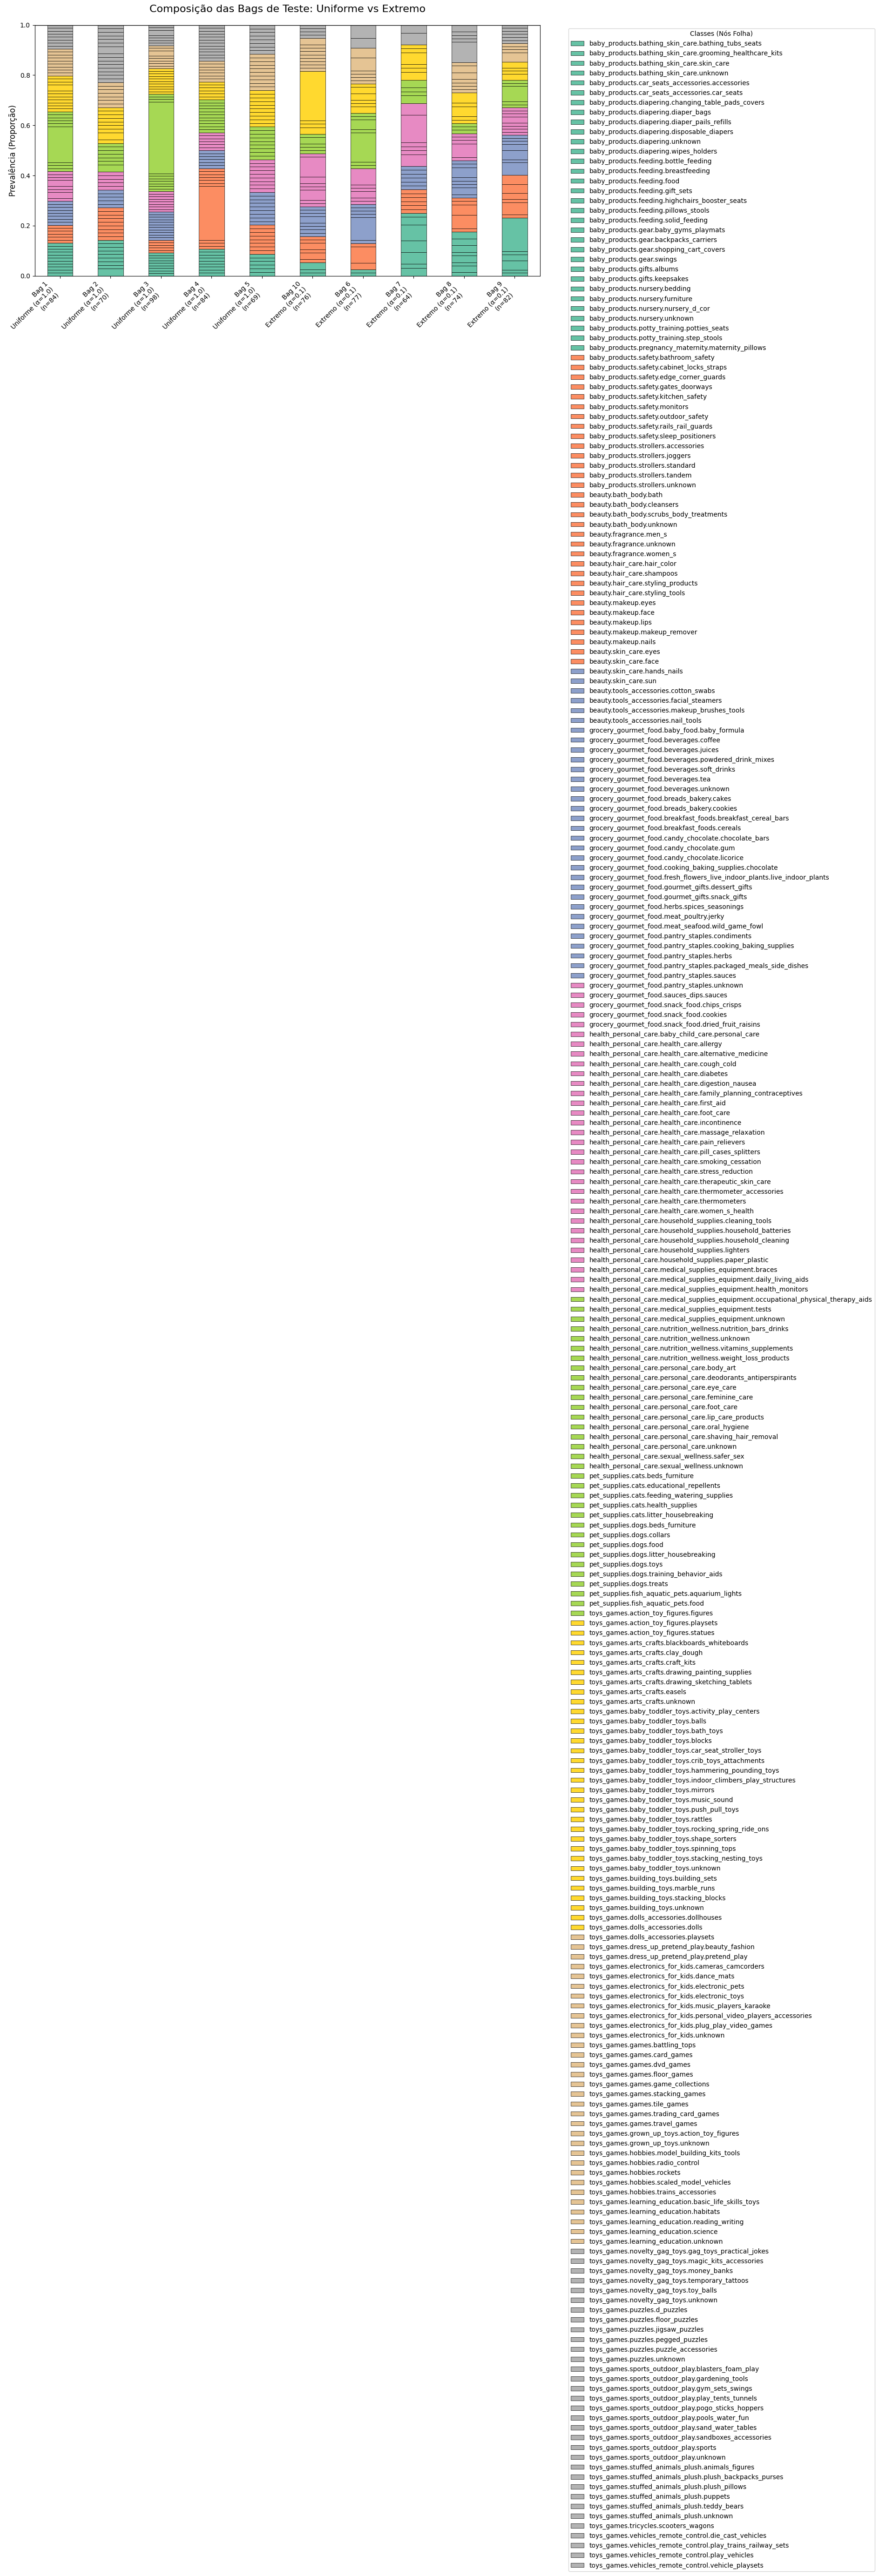

In [7]:
visualizar_shifts_das_bags(bags_generated)